# Propagation with analytic phase: semi-analytical and homeomorphic Fourier transforms

A field behind a lens, near a point source or far from a waist has a strongly
curved wavefront. Sampled as a complex array, its phase must change by less
than $\pi$ between neighbouring samples: a beam of width $L$ with the radius of
curvature $R$ needs about $L^2/(\lambda |R|)$ samples per axis, often
thousands, although its *amplitude* is smooth and needs only a few dozen.

Wyrowski and coworkers (Wang et al. 2019, 2020) therefore write the field as

$$ u(x, y) = A(x, y)\, e^{i\psi(x, y)}, $$

with a smooth, sampled amplitude $A$ and a phase $\psi$ that is known
analytically, and carry $\psi$ through the operators of the propagation in
closed form. `pyoptics.analytic_phase` does this for a separable quadratic
phase $\psi = \alpha_x x^2 + \alpha_y y^2 + \beta_x x + \beta_y y + \gamma$ (spherical or
astigmatic wavefront, $\alpha = k/(2R)$, with a tilt $\beta$):

| Function | What it does |
|---|---|
| `QuadraticPhaseField` | amplitude, grid and analytic phase of a field or a spectrum |
| `semi_analytical_FT()`, `inverse_semi_analytical_FT()` | exact Fourier transforms that keep the quadratic phase analytic (SFT) |
| `propagate()` | angular spectrum (or Fresnel) propagation with SFTs: the same small $N$ at any distance |
| `tilted_plane()` | the same onto a tilted plane |
| `homeomorphic_FT()` | pointwise (stationary phase) Fourier transform for any smooth phase (HFT) |
| `geometric_propagation()` | HFT, transfer function and inverse HFT: geometrical optics with amplitude transport |

**Semi-analytical Fourier transform.** Completing the square gives, per axis and exactly,

$$ \int A(x)\, e^{i(\alpha x^2 + \beta x)}\, e^{-ikx}\,dx
   = e^{-i\kappa^2/(4\alpha)}\,(A * c)\!\left(\tfrac{\kappa}{2\alpha}\right),
   \qquad \kappa = k - \beta,\quad c(u) = e^{i\alpha u^2}. $$

The spectrum is again "amplitude times quadratic phase": the phase
$-\kappa^2/(4\alpha)$ is analytic, the amplitude $A * c$ lives on the grid $k_j = \beta + 2\alpha x_j$
and is computed with FFTs, since the spectrum of the chirp $c$ is known in closed
form. The convolution with $c$ is a mild blur where $\alpha$ is large; for
$\alpha \to \infty$ it is the identity and the SFT becomes the *pointwise*
(homeomorphic) transform.

Conventions as everywhere in pyoptics: fields vary as $\exp(i(\mathbf k\cdot\mathbf r-\omega t))$,
lengths are in µm.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.analytic_phase import (QuadraticPhaseField, semi_analytical_FT, propagate,
                                     tilted_plane, homeomorphic_FT, geometric_propagation)
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics import tilted
from pyoptics.geometry import R_y
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
CMAP = "magma_r"          # zero intensity is white
t_start = time.time()

WL = 0.5                   # wavelength [µm]
K = 2*np.pi/WL

# a lens with f = 8 mm and an aperture of 2 mm diameter (NA 0.125), soft (super-Gaussian) edge
f, a_ap, L = 8000.0, 1000.0, 2400.0

def aperture(x, y):
    R2 = x[None, :]**2 + y[:, None]**2
    return np.exp(-(R2/a_ap**2)**8)

def timed(func, *args, repeat=3, **kwargs):
    best = np.inf
    for _ in range(repeat):
        t = time.perf_counter()
        out = func(*args, **kwargs)
        best = min(best, time.perf_counter() - t)
    return out, best

## 1. The sampling problem

Behind the lens the phase $-k r^2/(2f)$ changes fastest at the rim of the
aperture, by $k a\,\Delta x/f$ per sample. Sampling the complete field needs
$N \gtrsim L\,k\,(L/2)/(\pi f) = L^2/(\lambda f)$ samples over the window $L$ for the phase alone, here 1440,
plus those of the amplitude: about 1600 per axis ($2.7\cdot 10^6$ samples). The amplitude alone is resolved by 192. Below: a cut through
$\mathrm{Re}\,u$ on 192 samples (aliased: the moiré has nothing to do with the field) and
on 4096 samples, and the smooth amplitude that `QuadraticPhaseField` stores
instead.

samples of the window:           192
samples the full field needs:    1632
chirp ratio rho = |a| N dx²/pi: 7.5  (> 1: the SFT is used)


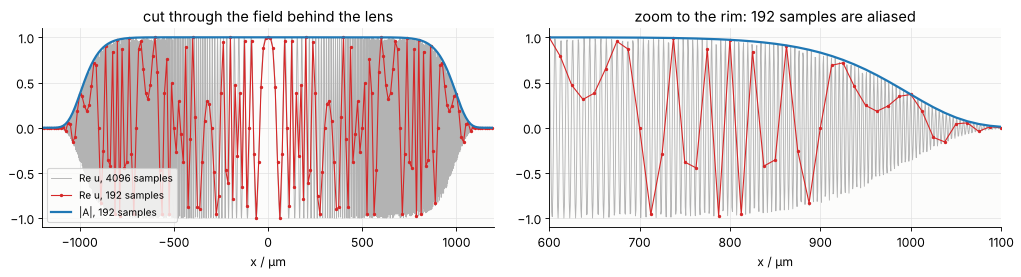

In [2]:
N = 192
x = grid1d(-L/2, L/2, N)
F0 = QuadraticPhaseField.from_curvature(aperture(x, x), x, x, WL, R=-f)
print("samples of the window:          ", N)
print("samples the full field needs:   ", F0.required_samples()[0])
print("chirp ratio rho = |a| N dx²/pi: {:.1f}  (> 1: the SFT is used)".format(F0.chirp_ratio()[0]))

x_fine = grid1d(-L/2, L/2, 4096)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a_ in ax:
    a_.plot(x_fine, np.cos(-K*x_fine**2/(2*f))*aperture(x_fine, np.zeros(1))[0], color="0.7",
            lw=0.8, label="Re u, 4096 samples")
    a_.plot(x, F0.field()[N//2].real, "C3.-", ms=4, lw=1, label="Re u, 192 samples")
    a_.plot(x, np.abs(F0.amplitude[N//2]), "C0", lw=2, label="|A|, 192 samples")
    a_.set(xlabel="x / µm")
ax[0].set(xlim=(-L/2, L/2), title="cut through the field behind the lens")
ax[1].set(xlim=(600, 1100), title="zoom to the rim: 192 samples are aliased")
ax[0].legend(loc="lower left", fontsize=9)
plt.tight_layout()

## 2. The SFT is exact, and when it is needed

A Gaussian beam behind the lens has an analytic spectrum,
$\int e^{-a x^2} e^{-ikx}dx = \sqrt{\pi/a}\,e^{-k^2/(4a)}$ with $a = 1/w^2 + i k/(2f)$. Its
transform is computed on $N$ samples over the same window, once with the SFT
and once with the ordinary FFT of the complete field (`mode="fft"`, here
evaluated on the same output frequencies with a chirp-z transform).

The two branches are complementary. The chirp $e^{i\alpha x^2}$ is sampled in $x$ if
$\rho = |\alpha| N\Delta x^2/\pi < 1$, its counterpart $e^{-i\nu^2/(4\alpha)}$ in the convolution of the SFT
if $\rho > 1$. With $\Delta x = L/N$, $\rho = |\alpha| L^2/(\pi N)$: the FFT needs *many* samples, the
SFT works for *few*. `mode="auto"` picks the branch per axis.

N =    32  rho =  45.00   SFT 1.2e-08   FFT 3.2e+00
N =    48  rho =  30.00   SFT 2.6e-08   FFT 7.9e+00
N =    64  rho =  22.50   SFT 4.1e-08   FFT 2.7e+00
N =    96  rho =  15.00   SFT 5.2e-08   FFT 2.8e+00
N =   128  rho =  11.25   SFT 4.1e-08   FFT 3.0e+00
N =   192  rho =   7.50   SFT 4.0e-08   FFT 1.5e+00
N =   256  rho =   5.62   SFT 4.2e-08   FFT 8.4e-01
N =   384  rho =   3.75   SFT 4.1e-08   FFT 3.3e-01
N =   512  rho =   2.81   SFT 4.0e-08   FFT 1.3e-01
N =   768  rho =   1.88   SFT 3.9e-08   FFT 1.0e-02
N =  1024  rho =   1.41   SFT 3.9e-08   FFT 3.1e-04
N =  1536  rho =   0.94   SFT 3.9e-08   FFT 4.2e-08
N =  2048  rho =   0.70   SFT 3.9e-08   FFT 4.0e-08


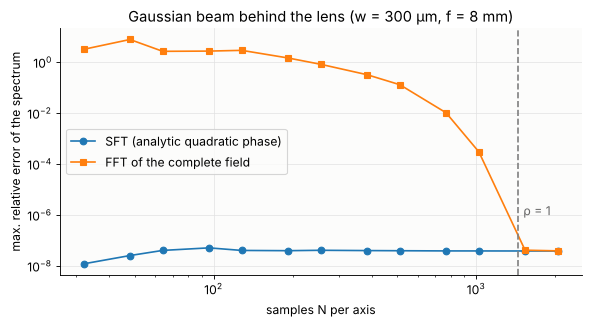

In [3]:
w_g = 300.0
a_g = 1/w_g**2 + 1j*K/(2*f)
Ns = np.array([32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048])
err = {"sft": [], "fft": []}
rho = []
for n_ in Ns:
    xg = grid1d(-L/2, L/2, n_)
    A_g = np.exp(-(xg[None, :]**2 + xg[:, None]**2)/w_g**2)
    Fg = QuadraticPhaseField.from_curvature(A_g, xg, xg, WL, R=-f)
    rho.append(Fg.chirp_ratio()[0])
    S = semi_analytical_FT(Fg, mode="sft")
    KX, KY = np.meshgrid(S.x, S.y)
    U_exact = np.pi/a_g*np.exp(-(KX**2 + KY**2)/(4*a_g))
    err["sft"].append(np.abs(S.field() - U_exact).max()/np.abs(U_exact).max())
    S_f = semi_analytical_FT(Fg, mode="fft", kx_out=S.x, ky_out=S.y)
    err["fft"].append(np.abs(S_f.field() - U_exact).max()/np.abs(U_exact).max())

N_rho1 = Ns[np.argmin(np.abs(np.array(rho) - 1))]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.loglog(Ns, err["sft"], "o-", label="SFT (analytic quadratic phase)")
ax.loglog(Ns, err["fft"], "s-", label="FFT of the complete field")
ax.axvline(K/(2*f)*L**2/np.pi, color="0.5", ls="--")
ax.text(K/(2*f)*L**2/np.pi*1.05, 1E-6, "ρ = 1", color="0.4")
ax.set(xlabel="samples N per axis", ylabel="max. relative error of the spectrum",
       title="Gaussian beam behind the lens (w = 300 µm, f = 8 mm)")
ax.legend()
plt.tight_layout()
for n_, e1, e2, r in zip(Ns, err["sft"], err["fft"], rho):
    print("N = {:5d}  rho = {:6.2f}   SFT {:.1e}   FFT {:.1e}".format(n_, r, e1, e2))

The SFT is exact from the smallest $N$ on (the Gaussian amplitude is resolved
by 32 samples) for all $\rho$; the FFT needs $\rho < 1$, i.e. $N > 1440$. Near $\rho = 1$ both work, which is where `"auto"` switches.

## 3. Through focus with 192 × 192 samples

`propagate()` does a forward SFT, multiplies the spectrum by $e^{ik_z z}$ and
transforms back. The paraxial part of the transfer function, $e^{ikz}e^{-iz(k_x^2+k_y^2)/(2k)}$
(more precisely: the best fitting separable quadratic of $k_z z$ over the spectrum),
is added to the analytic quadratic phase of the spectrum; only the small
non-paraxial remainder multiplies the sampled amplitude. The spectrum's
quadratic coefficient $f/(2k) - z/(2k)$ vanishes at the focus, where the inverse
transform turns into an ordinary FFT (or a chirp-z transform onto a chosen
window). Away from the focus the output grid simply scales with the beam,
$x \to x\,(f - z)/f$.

The side view below has 300 planes, each a full 2D propagation of the
192 × 192 field, evaluated on a fixed window ($x$ = –1.2 … 1.2 mm, $y = 0$) and,
on the right, on a 40 µm window around the focus.

461 planes in 9.6 s (20.8 ms per plane)


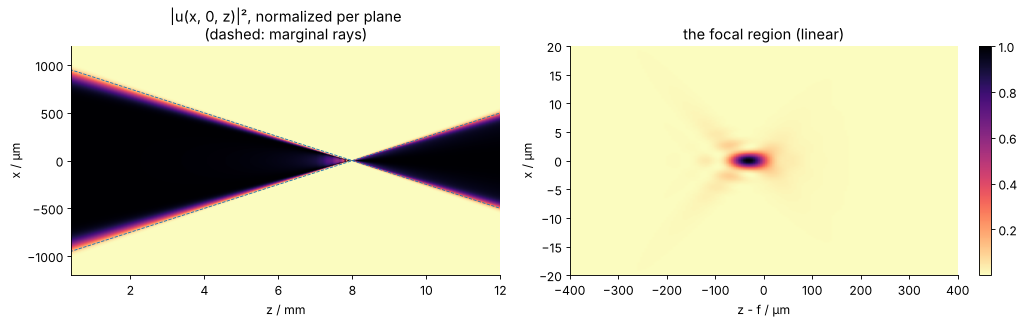

In [4]:
zs = np.linspace(0.05*f, 1.5*f, 300)
x_side = np.linspace(-1200, 1200, 481)
x_near = np.linspace(-20, 20, 161)
zs_near = np.linspace(f - 400, f + 400, 161)
t = time.perf_counter()
side = np.array([propagate(F0, z, x_out=x_side, y_out=np.zeros(1)).intensity()[0] for z in zs])
near = np.array([propagate(F0, z, x_out=x_near, y_out=np.zeros(1)).intensity()[0] for z in zs_near])
t_side = time.perf_counter() - t
print("{} planes in {:.1f} s ({:.1f} ms per plane)".format(len(zs) + len(zs_near), t_side,
                                                         1E3*t_side/(len(zs) + len(zs_near))))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].imshow(side.T/side.max(axis=1), extent=[zs[0]/1E3, zs[-1]/1E3, x_side[0], x_side[-1]],
             aspect="auto", cmap=CMAP, vmin=0, vmax=1)
ax[0].plot([0, f/1E3, 1.5*f/1E3], [a_ap, 0, -0.5*a_ap], "C0--", lw=0.8)
ax[0].plot([0, f/1E3, 1.5*f/1E3], [-a_ap, 0, 0.5*a_ap], "C0--", lw=0.8)
ax[0].set(xlabel="z / mm", ylabel="x / µm", xlim=(zs[0]/1E3, zs[-1]/1E3),
          title="|u(x, 0, z)|², normalized per plane\n(dashed: marginal rays)")
im = ax[1].imshow(near.T/near.max(), extent=[(zs_near[0] - f), (zs_near[-1] - f), x_near[0], x_near[-1]],
                  aspect="auto", cmap=CMAP)
ax[1].set(xlabel="z - f / µm", ylabel="x / µm", title="the focal region (linear)")
for a_ in ax:
    a_.grid(False)
plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout()

### Comparison with the angular spectrum method

The reference is `rayleigh_sommerfeld_I_TF()` on the fully sampled field, 2048 × 2048
samples over the same window. Both are exact angular spectrum propagation; the
table compares them at four planes, on the reference's own grid points (the
analytic-phase result is evaluated there with `x_out`, `y_out`).

 z / mm   ASM 2048² [s]   analytic phase 192² [s]   max. rel. difference
  4.00           1.09                 0.029       5.6e-06
  7.60           0.93                 0.012       1.2e-06
  8.00           0.38                 0.017       3.8e-08
 10.40           0.45                 0.031       4.2e-06


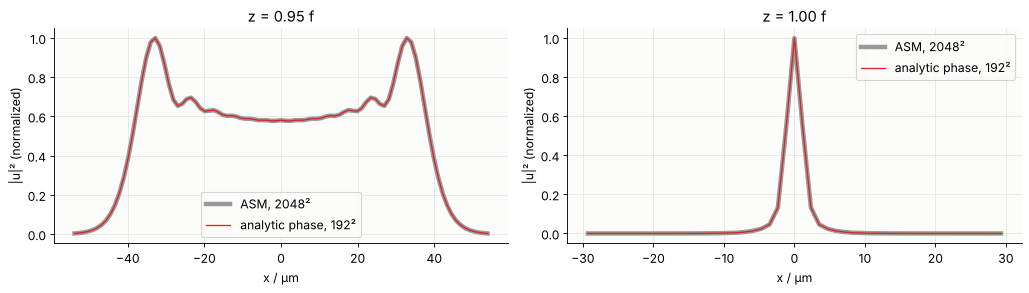

In [5]:
Nr = 2048
xr = grid1d(-L/2, L/2, Nr)
U_ref0 = aperture(xr, xr)*np.exp(-1j*K*(xr[None, :]**2 + xr[:, None]**2)/(2*f))

rows = []
cuts = {}
for z in (0.5*f, 0.95*f, f, 1.3*f):
    (U_ref, _, _), t_ref = timed(rayleigh_sommerfeld_I_TF, U_ref0, xr, xr, z, WL, repeat=1)
    # window: the geometric beam (or 30 µm around the focus), every 4th reference sample
    half = max(30.0, 1.1*a_ap*abs(f - z)/f)
    sel = np.where(np.abs(xr) <= half)[0][::4 if half > 100 else 1]
    x_cmp = xr[sel]
    G, t_sft = timed(propagate, F0, z, x_out=x_cmp, y_out=x_cmp)
    ref = U_ref[np.ix_(sel, sel)]
    e = np.abs(G.field() - ref).max()/np.abs(ref).max()
    rows.append((z, t_ref, t_sft, e))
    cuts[z] = (x_cmp, np.abs(ref[len(sel)//2])**2, G.intensity()[len(sel)//2])

print(" z / mm   ASM 2048² [s]   analytic phase 192² [s]   max. rel. difference")
for z, t1, t2, e in rows:
    print("{:6.2f}   {:12.2f}    {:18.3f}       {:.1e}".format(z/1E3, t1, t2, e))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a_, z in zip(ax, (0.95*f, f)):
    xc, Ir, Ia = cuts[z]
    a_.plot(xc, Ir/Ir.max(), color="0.6", lw=4, label="ASM, 2048²")
    a_.plot(xc, Ia/Ir.max(), "C3", lw=1.2, label="analytic phase, 192²")
    a_.set(xlabel="x / µm", ylabel="|u|² (normalized)", title="z = {:.2f} f".format(z/f))
    a_.legend()
plt.tight_layout()

The focus lies about 30 µm *before* $z = f$: a quadratic phase is a paraxial
lens, and exact (non-paraxial) propagation shows its spherical aberration, the
marginal rays crossing the axis at $f\cos\theta \approx f - 62$ µm. Both methods agree on
this to about $10^{-5}$ and better, with $1/100$ of the samples and a
fraction of the run time per plane. The remaining difference is the sampling
of the amplitude's soft edge and of the non-paraxial remainder of
$k_z z$: for higher NA this remainder grows ($\propto z\,\mathrm{NA}^4$), and `propagate()` issues a
`RuntimeWarning` when it is no longer sampled (then more samples, or the
spherical instead of the quadratic reference phase, are needed: the
"generalized Debye integral" of Wang et al. 2020).

## 4. The pointwise limit: homeomorphic Fourier transform and geometrical optics

If the phase dominates, the Fourier integral is given by its stationary point
alone: the sample at $x$ is mapped to the spatial frequency $k = \nabla\psi(x)$ and

$$ U(k) = A(x)\,\frac{2\pi}{\sqrt{|\det H|}}\,e^{i\pi\sigma(H)/4}\,e^{i(\psi(x) - k\cdot x)} $$

($H$: Hessian of $\psi$, $\sigma$: its signature). This homeomorphic Fourier
transform (HFT) needs no FFT at all, only $O(N)$ pointwise operations, and
the phase may be *any* smooth function, given as an unwrapped array. Its
error is of the order of the inverse Fresnel number: for the Gaussian behind
the lens $2f/(k w^2)$, the ratio of the beam's own diffraction to the
focusing.

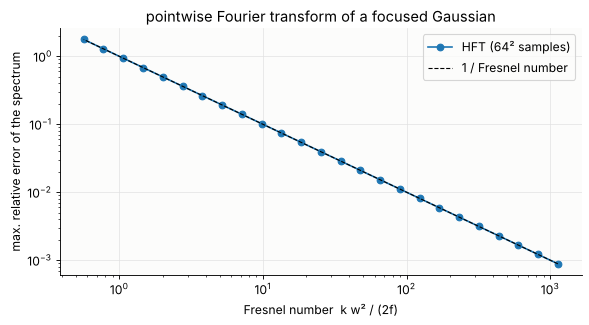

In [6]:
fs = np.geomspace(500, 1E6, 25)
xg = grid1d(-L/2, L/2, 64)
XG, YG = np.meshgrid(xg, xg)
A_g = np.exp(-(XG**2 + YG**2)/w_g**2)
err_hft = []
for f_ in fs:
    kx, ky, U_amp, U_ph = homeomorphic_FT(A_g, -K*(XG**2 + YG**2)/(2*f_), xg, xg)
    a_ = 1/w_g**2 + 1j*K/(2*f_)
    U_ex = np.pi/a_*np.exp(-(kx**2 + ky**2)/(4*a_))
    err_hft.append(np.abs(U_amp*np.exp(1j*U_ph) - U_ex).max()/np.abs(U_ex).max())

fresnel = K*w_g**2/(2*fs)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.loglog(fresnel, err_hft, "o-", label="HFT (64² samples)")
ax.loglog(fresnel, 1/fresnel, "k--", lw=1, label="1 / Fresnel number")
ax.set(xlabel="Fresnel number  k w² / (2f)", ylabel="max. relative error of the spectrum",
       title="pointwise Fourier transform of a focused Gaussian")
ax.legend()
plt.tight_layout()

Chaining HFT, transfer function and inverse HFT gives `geometric_propagation()`:
each sample travels along its ray to $x + z\,\nabla\psi/k_z$, its amplitude scales with
$1/\sqrt{|\det(I - zHG)|}$ (the ray tube's cross section; $G$ is the Hessian of $k_z$), it
collects the phase $z k^2/k_z$ and $-\pi/2$ per crossed focal line (Gouy phase).
That is geometrical optics with amplitude transport, the limit in which
Wyrowski's field tracing connects to ray tracing. Below: the lens field at
$z = 0.5f$ and $z = 0.97f$ by geometric propagation (64 × 64 samples, no FFT) and by
`propagate()`. Far from focus they agree up to the diffraction at the soft
edge; close to the focus the pointwise picture fails (the geometric intensity
diverges at $z = f$).

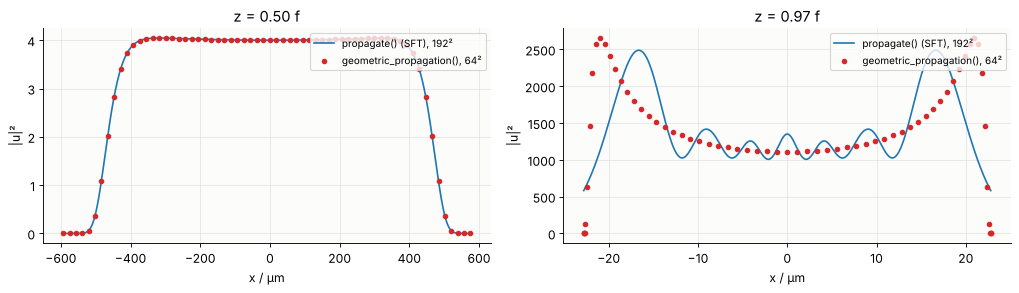

In [7]:
xg = grid1d(-L/2, L/2, 64)
XG, YG = np.meshgrid(xg, xg)
A_ap = aperture(xg, xg)
psi_lens = -K*(XG**2 + YG**2)/(2*f)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a_, z in zip(ax, (0.5*f, 0.97*f)):
    xz, yz, ua, ph = geometric_propagation(A_ap, psi_lens, xg, xg, z, WL)
    x_line = np.linspace(xz[32].min(), xz[32].max(), 600)
    G = propagate(F0, z, x_out=x_line, y_out=np.zeros(1))
    a_.plot(x_line, G.intensity()[0], "C0", label="propagate() (SFT), 192²")
    a_.plot(xz[32], np.abs(ua[32])**2, "C3o", ms=4, label="geometric_propagation(), 64²")
    a_.set(xlabel="x / µm", ylabel="|u|²", title="z = {:.2f} f".format(z/f))
    a_.legend(loc="upper right", fontsize=9)
plt.tight_layout()

## 5. Tilted planes

**Does this also work for tilted planes? Yes.** Propagation onto a plane with
a rotated normal is a coordinate transformation of the spectrum (Matsushima,
Schimmel and Wyrowski 2003, notebook 03): the plane wave with wave vector
$\mathbf k$ reaches the plane with $\hat{\mathbf k} = R^T\mathbf k$, and the spectrum must be
resampled on a uniform $\hat k$ grid, with the Jacobian $k_z/\hat k_z$. In
`pyoptics.tilted` this needs the *complete* field (fully sampled) and an
interpolation of its spectrum, which for a curved beam is itself a strongly
oscillating chirp (hence the padding there). With the analytic phase,
`analytic_phase.tilted_plane()`

1. computes the spectrum with an SFT: smooth amplitude $B(\mathbf k)$, analytic phase $\tilde\psi(\mathbf k)$;
2. sets up a uniform grid of $\hat{\mathbf k}$ over the rotated support, maps it back with $\mathbf k = R\hat{\mathbf k}$
   and interpolates only the *smooth amplitude* $B$ there;
3. evaluates the phase $\tilde\psi(\mathbf k) + \mathbf k\cdot\mathbf r_0$ *exactly* at the new points, keeps its best
   separable quadratic in $\hat k$ (including the linear carrier, which Zhang et al. 2016
   also treat analytically) as the analytic phase and samples only the small remainder;
4. transforms back with an inverse SFT in the plane's own coordinates $(\hat x, \hat y)$.

The remainder that is not quadratic in $\hat k$ (the tilt mixes $k_x$ and $k_z$, which
gives coma-like cubic terms) must be sampled; `N_out` sets the samples of the
target spectrum (default: twice the source) and a `RuntimeWarning` reports
undersampling.

Example: a Gaussian beam ($w$ = 40 µm) behind a lens with $f$ = 200 µm (the full
field needs about 480 samples per axis over the 220 µm window) and a plane through
$z_0$ = 120 µm, tilted by 45° about $y$. Reference: `tilted.tilted_plane(method="exact")`, the
exact non-uniform plane wave sum, on 512² samples.

full field needs 549 samples per axis, the analytic-phase field has 64


exact sum, 512²:              2.163 s   (reference)
analytic phase, 64²:          0.077 s   max. rel. difference 2.6e-04
exact sum on the 64² field:              max. rel. difference 1.5e+00  (aliased input)


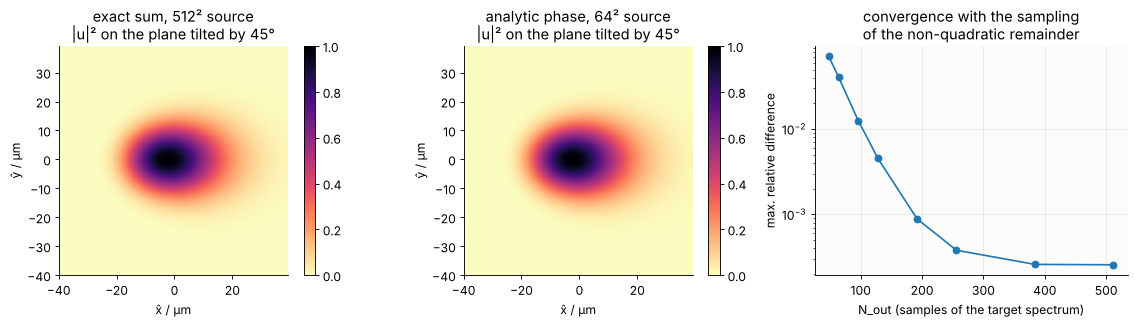

In [8]:
w_t, f_t, z0, Lt = 40.0, 200.0, 120.0, 220.0
Rt = R_y(np.radians(45))
x_t_out = grid1d(-40, 40, 96)

xr_t = grid1d(-Lt/2, Lt/2, 512)
R2 = xr_t[None, :]**2 + xr_t[:, None]**2
U_t0 = np.exp(-R2/w_t**2)*np.exp(-1j*K*R2/(2*f_t))
t = time.perf_counter()
u_ref, _, _, _ = tilted.tilted_plane(U_t0, xr_t, xr_t, z0, WL, R=Rt, x_out=x_t_out, y_out=x_t_out,
                                     method="exact", remove_carrier=False)
t_ref = time.perf_counter() - t

x64 = grid1d(-Lt/2, Lt/2, 64)
A64 = np.exp(-(x64[None, :]**2 + x64[:, None]**2)/w_t**2)
F64 = QuadraticPhaseField.from_curvature(A64, x64, x64, WL, R=-f_t)
print("full field needs {} samples per axis, the analytic-phase field has 64".format(F64.required_samples()[0]))
T, t_ana = timed(tilted_plane, F64, z0, R=Rt, x_out=x_t_out, y_out=x_t_out, N_out=384)
e_ana = np.abs(T.field() - u_ref).max()/np.abs(u_ref).max()

# the standard method on the same 64² grid sees an aliased field
u_bad, _, _, _ = tilted.tilted_plane(F64.field(), x64, x64, z0, WL, R=Rt, x_out=x_t_out,
                                     y_out=x_t_out, method="exact", remove_carrier=False)
e_bad = np.abs(u_bad - u_ref).max()/np.abs(u_ref).max()
print("exact sum, 512²:            {:7.3f} s   (reference)".format(t_ref))
print("analytic phase, 64²:        {:7.3f} s   max. rel. difference {:.1e}".format(t_ana, e_ana))
print("exact sum on the 64² field:              max. rel. difference {:.1e}  (aliased input)".format(e_bad))

errs_nout = []
N_outs = [48, 64, 96, 128, 192, 256, 384, 512]
for n_ in N_outs:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        Tn = tilted_plane(F64, z0, R=Rt, x_out=x_t_out, y_out=x_t_out, N_out=n_)
    errs_nout.append(np.abs(Tn.field() - u_ref).max()/np.abs(u_ref).max())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ext = [x_t_out[0], x_t_out[-1], x_t_out[0], x_t_out[-1]]
I_ref = np.abs(u_ref)**2
for a_, I, title in ((ax[0], I_ref, "exact sum, 512² source"),
                     (ax[1], T.intensity(), "analytic phase, 64² source")):
    im = a_.imshow(I/I_ref.max(), extent=ext, cmap=CMAP, vmin=0, vmax=1)
    a_.set(xlabel="x̂ / µm", ylabel="ŷ / µm", title=title + "\n|u|² on the plane tilted by 45°")
    plt.colorbar(im, ax=a_, fraction=0.046)
    a_.grid(False)
ax[2].semilogy(N_outs, errs_nout, "o-")
ax[2].set(xlabel="N_out (samples of the target spectrum)", ylabel="max. relative difference",
          title="convergence with the sampling\nof the non-quadratic remainder")
plt.tight_layout()

The footprint is stretched along $\hat x$ (by $1/\cos\theta$) and asymmetric: the plane
point $\hat x$ lies at $z = z_0 - \hat x\sin\theta$, so the half with $\hat x < 0$ is closer to the focus
and sees the smaller beam (a small effect here). With `N_out=384` (the target spectrum, cheap) the
analytic-phase result agrees with the exact sum to about $10^{-4}$ from 64² instead
of 512² source samples, about a hundred times faster, while the exact sum on the same
64² samples of the complete field is useless (aliased).

## 6. Notes

- **What is analytic.** A separable quadratic phase with a linear carrier.
  Rotated astigmatism ($xy$ terms) and higher orders (e.g. spherical
  aberration, the non-paraxial part of a spherical wave) stay in the sampled
  amplitude, which must then resolve them. `QuadraticPhaseField.from_field()`
  splits a known curvature off a sampled field.
- **Branches.** Per axis, the SFT is used for $\rho = |\alpha|N\Delta x^2/\pi \ge 1$ and the FFT
  (phase multiplied into the amplitude) otherwise. Behind an FFT step the
  amplitude carries the phase again; pass the desired output grid (`x_out`,
  `y_out`) to the transform instead of resampling afterwards
  (`resample()` warns in that case).
- **Windows.** The output grid of an SFT step is fixed by the input grid
  ($k_j = \beta + 2\alpha x_j$); arbitrary windows are obtained by interpolating the smooth
  amplitude. The source amplitude must decay inside its window: the chirp
  convolution spreads it slightly (zero padding `pad=2` avoids wrap-around).
- **Pointwise vs. semi-analytical.** The HFT and `geometric_propagation()` are
  $O(N)$ and accept any smooth phase, but are only valid at large Fresnel
  numbers away from foci and caustics. The SFT is exact everywhere, including
  the focus.
- **Tilted planes.** Implemented with the SFT (semi-analytically). The
  pointwise version would map each ray onto the tilted plane (ray tracing
  with amplitude transport) and is not implemented.

Tests: `test/test_analytic_phase.py` checks the SFT and the paraxial
propagation of focused, astigmatic and tilted Gaussian beams against
closed-form results (to $10^{-8}$, before, at and behind the focus), the
non-paraxial propagation against `rayleigh_sommerfeld_I_TF()`, the tilted
plane against `tilted.tilted_plane()`, the HFT error against the inverse
Fresnel number, and the ray mapping, Gouy phase and power conservation of
`geometric_propagation()`.

In [9]:
print("run time of the notebook: {:.0f} s".format(time.time() - t_start))

run time of the notebook: 27 s


## References

- Z. Wang, S. Zhang, O. Baladron-Zorita, C. Hellmann and F. Wyrowski, "Application of the semi-analytical Fourier transform to electromagnetic modeling", Opt. Express 27, 15335-15350 (2019).
- Z. Wang, O. Baladron-Zorita, C. Hellmann and F. Wyrowski, "Theory and algorithm of the homeomorphic Fourier transform for optical simulations", Opt. Express 28, 10552-10571 (2020).
- Z. Wang, O. Baladron-Zorita, C. Hellmann and F. Wyrowski, "Generalized Debye integral", Opt. Express 28, 24459-24470 (2020).
- F. Wyrowski and M. Kuhn, "Introduction to field tracing", J. Mod. Opt. 58, 449-466 (2011).
- S. Zhang, D. Asoubar, C. Hellmann and F. Wyrowski, "Propagation of electromagnetic fields between non-parallel planes: a fully vectorial formulation and an efficient implementation", Appl. Opt. 55, 529-538 (2016).
- K. Matsushima, H. Schimmel and F. Wyrowski, "Fast calculation method for optical diffraction on tilted planes by use of the angular spectrum of plane waves", J. Opt. Soc. Am. A 20, 1755-1762 (2003).
- J. W. Goodman, *Introduction to Fourier Optics*, 4th ed., W. H. Freeman (2017).